# generation et extraction de parametres avec statsmodels

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf
from scipy.signal import find_peaks

from series_utils import generate_series

## Partie 1 : generation avec statsmodels

### AR(p)

ici on choisit les coefficients a_i directement, contrairement a generateur ou on les estimait a partir d'une serie deja generee

stationnaire : True


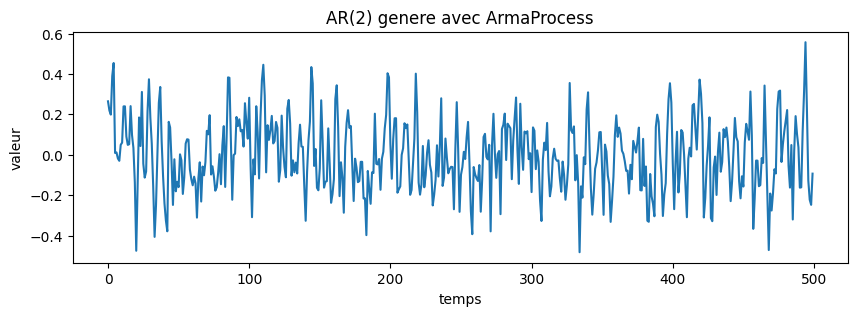

In [42]:
ar_coefs = np.array([1, -0.6, 0.3])
ma_coefs = np.array([1])

ar_process = ArmaProcess(ar_coefs, ma_coefs)
print("stationnaire :", ar_process.isstationary)

np.random.seed(0)
series_ar = ar_process.generate_sample(nsample=500, scale=0.15)

plt.figure(figsize=(10, 3))
plt.plot(series_ar)
plt.title("AR(2) genere avec ArmaProcess")
plt.xlabel("temps")
plt.ylabel("valeur")
plt.show()

### ARMA(p,q)

stationnaire : True


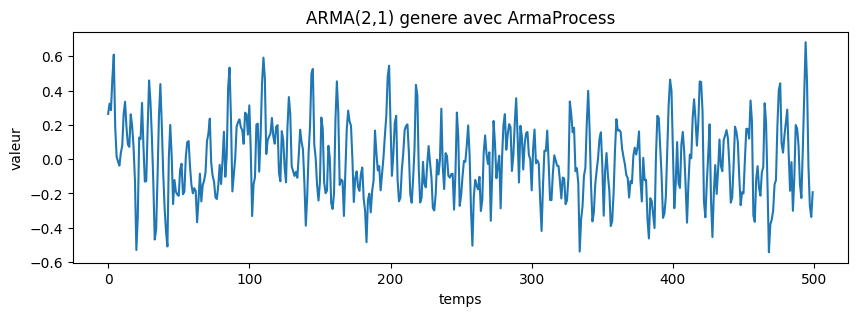

In [43]:
ar_coefs = np.array([1, -0.6, 0.3])
ma_coefs = np.array([1, 0.4])

arma_process = ArmaProcess(ar_coefs, ma_coefs)
print("stationnaire :", arma_process.isstationary)

np.random.seed(0)
series_arma = arma_process.generate_sample(nsample=500, scale=0.15)

plt.figure(figsize=(10, 3))
plt.plot(series_arma)
plt.title("ARMA(2,1) genere avec ArmaProcess")
plt.xlabel("temps")
plt.ylabel("valeur")
plt.show()

### AR(2) resonant

un AR(2) dont les racines complexes sont proches du cercle unite produit une oscillation quasi periodique, sans ecrire de sinus explicitement. ca correspond a la recurrence x[n] = 2cos(2pi/T)x[n-1] - x[n-2] avec r<1

stationnaire : True


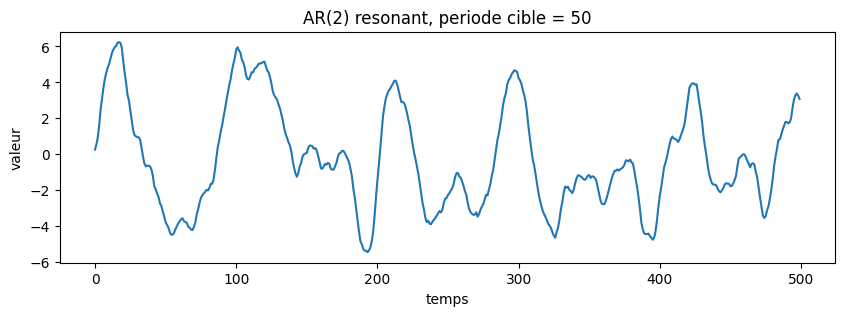

In [44]:
periode_cible = 50
r = 0.95

phi1 = 2 * r * np.cos(2 * np.pi / periode_cible)
phi2 = -r ** 2

ar_coefs = np.array([1, -phi1, -phi2])
ma_coefs = np.array([1])

resonant_process = ArmaProcess(ar_coefs, ma_coefs)
print("stationnaire :", resonant_process.isstationary)

np.random.seed(0)
series_resonant = resonant_process.generate_sample(nsample=500, scale=0.15)

plt.figure(figsize=(10, 3))
plt.plot(series_resonant)
plt.title(f"AR(2) resonant, periode cible = {periode_cible}")
plt.xlabel("temps")
plt.ylabel("valeur")
plt.show()

### Comparaison visuelle

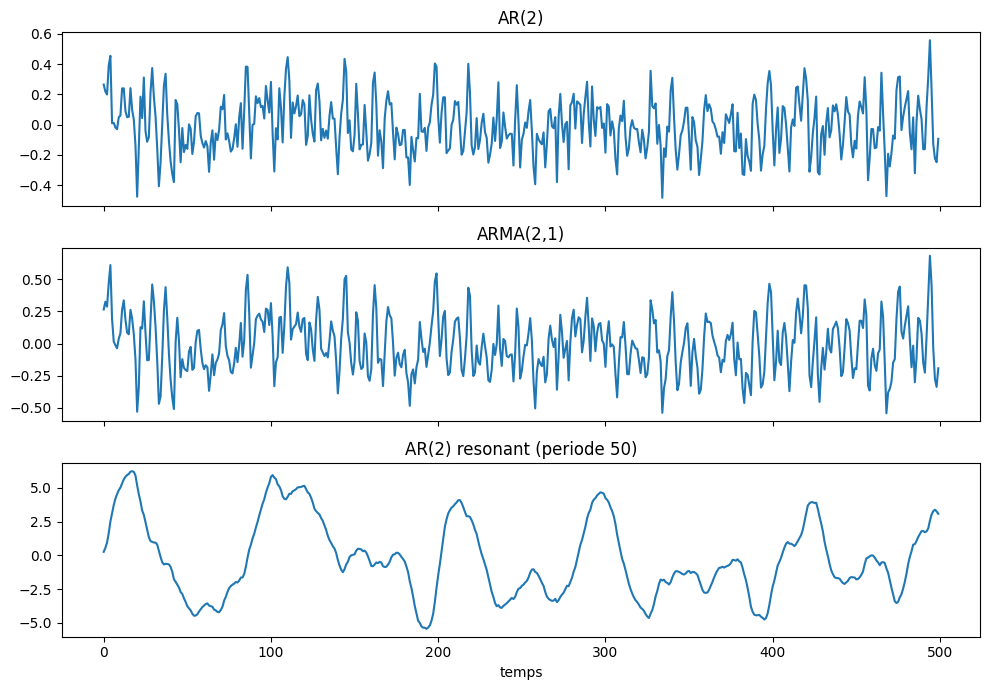

In [45]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

axes[0].plot(series_ar)
axes[0].set_title("AR(2)")

axes[1].plot(series_arma)
axes[1].set_title("ARMA(2,1)")

axes[2].plot(series_resonant)
axes[2].set_title("AR(2) resonant (periode 50)")
axes[2].set_xlabel("temps")

plt.tight_layout()
plt.show()

contrairement a generate_series, le bruit d'un instant se propage dans les instants suivants via la recurrence, ce qui donne une dynamique differente meme quand l'allure parait similaire



generate_series : $x[t] = \text{trend}(t) + \text{saisonnalité}(t) + \varepsilon[t]$. C'est une formule fermée qui ne dépend que de $t$ — pas de $x[t-1]$ dans la formule. Donc $\varepsilon[t]$ ne peut physiquement pas atteindre $x[t+1]$, puisque la formule de $x[t+1]$ ne fait référence qu'à $t+1$ et à son propre bruit $\varepsilon[t+1]$, jamais à $x[t]$.

AR/ARMA : $x[n] = \phi_1 x[n-1] + \phi_2 x[n-2] + \varepsilon[n]$. Ici $x[n-1]$ apparaît explicitement dans la formule de $x[n]$. Et $x[n-1]$ a lui-même été défini de la même façon : $x[n-1] = \phi_1 x[n-2] + \phi_2 x[n-3] + \varepsilon[n-1]$ — donc $\varepsilon[n-1]$ est "contenu dans" $x[n-1]$. Quand on utilise $x[n-1]$ pour calculer $x[n]$, on récupère avec lui tout ce qu'il contient, y compris $\varepsilon[n-1]$ (et transitivement $\varepsilon[n-2]$, etc., avec un poids qui décroît). C'est cette chaîne de dépendance qui fait que le bruit se propage.

## Partie 2 : extraction de parametres

on reprend generate_series avec des parametres connus a l'avance, pour verifier que le pipeline d'extraction retrouve bien ces valeurs

In [46]:
true_params = dict(
    trend_slope=0.01,
    seasonal_amplitude=1.0,
    seasonal_period=50,
    noise_std=0.15,
)

rng = np.random.default_rng(0)
t, series = generate_series(800, rng=rng, **true_params)

### Periode (ACF)

meme methode que la slide f0-estimation (cf Oudre) : le premier pic de l'autocorrelation pour des lags positifs correspond a la periode

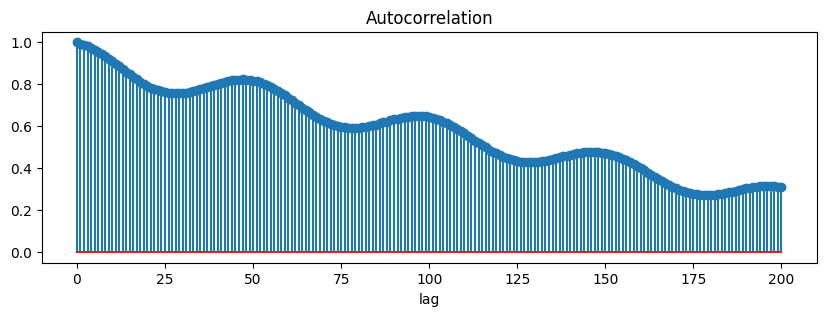

periode estimee : 47
periode reelle : 50


In [47]:
acf_values = acf(series, nlags=200)

plt.figure(figsize=(10, 3))
plt.stem(acf_values)
plt.title("Autocorrelation")
plt.xlabel("lag")
plt.show()

peaks, _ = find_peaks(acf_values, height=0.1)
periode_estimee = peaks[0]

print("periode estimee :", periode_estimee)
print("periode reelle :", true_params["seasonal_period"])

### Decomposition tendance / saisonnalite / residu

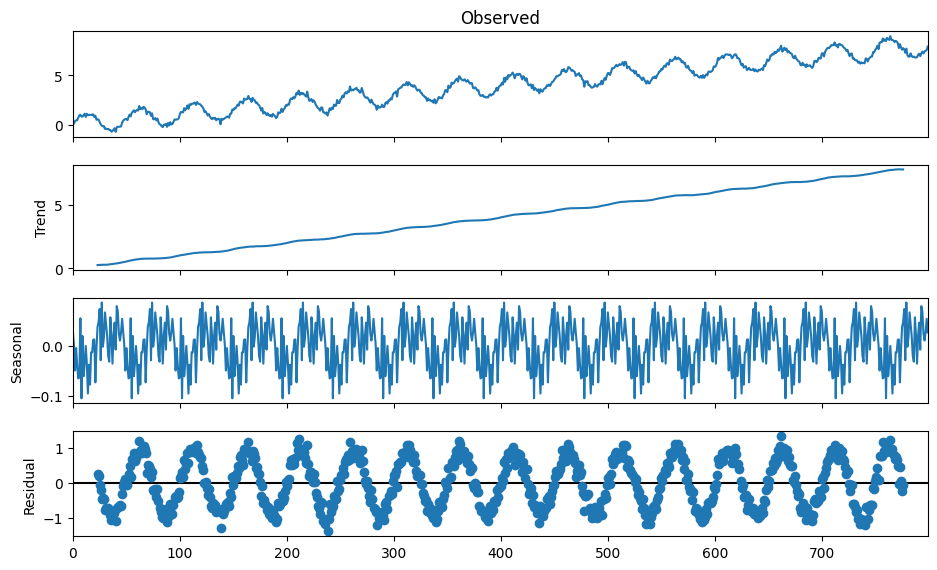

In [48]:
decomposition = seasonal_decompose(series, model="additive", period=periode_estimee)

fig = decomposition.plot()
fig.set_size_inches(10, 6)
plt.show()

### Tendance

In [49]:
trend_component = decomposition.trend
valid = ~np.isnan(trend_component)

pente_estimee = np.polyfit(t[valid], trend_component[valid], deg=1)[0]

print("pente estimee :", pente_estimee)
print("pente reelle :", true_params["trend_slope"])

pente estimee : 0.010001720415785767
pente reelle : 0.01


### Amplitude saisonniere

In [50]:
amplitude_estimee = (decomposition.seasonal.max() - decomposition.seasonal.min()) / 2

print("amplitude estimee :", amplitude_estimee)
print("amplitude reelle :", true_params["seasonal_amplitude"])

amplitude estimee : 0.09531321280767063
amplitude reelle : 1.0


### Bruit

In [51]:
bruit_estime = np.nanstd(decomposition.resid)

print("bruit estime :", bruit_estime)
print("bruit reel :", true_params["noise_std"])

bruit estime : 0.6821146668718562
bruit reel : 0.15


### Recapitulatif

In [52]:
comparaison = pd.DataFrame(dict(
    parametre=["periode", "pente", "amplitude", "bruit"],
    valeur_reelle=[true_params["seasonal_period"], true_params["trend_slope"],
                   true_params["seasonal_amplitude"], true_params["noise_std"]],
    valeur_estimee=[periode_estimee, pente_estimee, amplitude_estimee, bruit_estime],
))
comparaison

,parametre,valeur_reelle,valeur_estimee
0,periode,50.00,47.000000
1,pente,0.01,0.010002
2,amplitude,1.00,0.095313
3,bruit,0.15,0.682115


seasonal_decompose :

Tendance : chaque point de tendance est la moyenne des valeurs sur une période complète autour de lui.

détendancé = série − tendance

On regroupe les valeurs détendancées selon leur position dans le cycle : toutes les valeurs à la phase 0 (t = 0, 50, 100, ...), toutes celles à la phase 1 (t = 1, 51, 101, ...), etc.
Pour chaque phase, on prend la moyenne. On obtient un motif unique de longueur une période, qu'on recopie à l'identique sur toute la série. Le résidu est ce qui reste.

### STL

STL (Seasonal-Trend decomposition using LOESS)

Pour estimer la valeur lissee en un instant t, on ne garde que les points voisins de t, on ajuste une petite regression sur ces voisins en ponderant plus fort les plus proches, et la valeur de cette regression en t donne le point lissé. on deplace la fenetre sur toute la serie. contrairement a une moyenne mobile qui traite tous les voisins pareil, LOESS pondere par la distance

La tendance et la saisonnalite sont liees, donc STL alterne et affine les deux en plusieurs passages. a chaque passage :

on retire la tendance courante.

on regroupe le reste par phase du cycle (pour une periode de 50 : les instants 0, 50, 100 ... ensemble, puis 1, 51, 101 ... etc) et on lisse chaque groupe par LOESS. comme on lisse chaque phase le long du temps, la saisonnalite peut evoluer lentement d'un cycle a l'autre au lieu d'etre figee.

on retire cette saisonnalite, puis on lisse le reste par LOESS pour obtenir la nouvelle tendance.

le residu est ce qui reste : serie - tendance - saisonnalite. l'option robust donne un poids faible aux points aberrants (fort residu) pour qu'ils n'influencent presque plus la tendance ni la saisonnalite.

deux ponderations interviennent et se multiplient. par la distance  : un voisin a distance d du point lisse, h etant la distance au voisin le plus eloigne de la fenetre, recoit le poids tricube (1 - (d/h)^3)^3, proche de 1 pres du point et proche de 0 au bord. par la robustesse (option robus=true) : un point de residu r, s etant la mediane des valeurs absolues des residus, recoit le poids bicarre (1 - (r / 6s)^2)^2 si |r| < 6s sinon 0, proche de 0 si le point est aberrant. le poids final d'un point est le produit des deux.

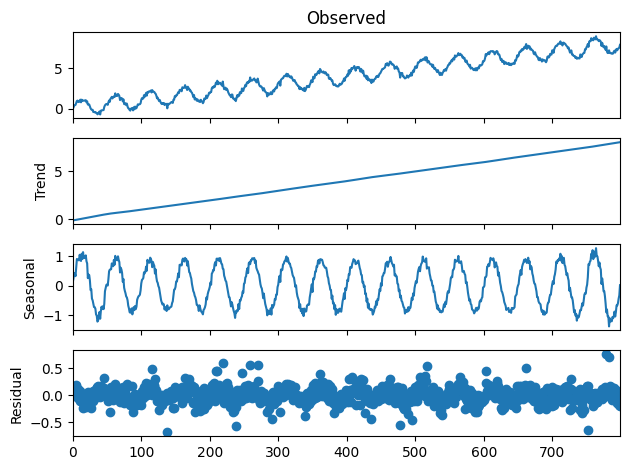

In [53]:
from statsmodels.tsa.seasonal import STL

stl = STL(series, period=periode_estimee, robust=True)
res = stl.fit()
fig = res.plot()

In [54]:
amplitude_stl = (res.seasonal.max() - res.seasonal.min()) / 2
bruit_stl = np.nanstd(res.resid)

print("amplitude estimee (STL) :", amplitude_stl)
print("amplitude reelle :", true_params["seasonal_amplitude"])
print("bruit estime (STL) :", bruit_stl)
print("bruit reel :", true_params["noise_std"])

amplitude estimee (STL) : 1.3341000557986522
amplitude reelle : 1.0
bruit estime (STL) : 0.15324785558080617
bruit reel : 0.15
